In [4]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define ticker as a variable at the top (Checklist item!)
TICKER = "SPY"

# Fetch 3 years of daily historical data
df = yf.download(TICKER, start="2023-01-01", end="2026-01-01")

# Clean data: Display data structure to confirm download
print(df.head())

[*********************100%***********************]  1 of 1 completed

Price            Close        High         Low        Open     Volume
Ticker             SPY         SPY         SPY         SPY        SPY
Date                                                                 
2023-01-03  365.072021  370.450018  362.205647  368.475207   74850700
2023-01-04  367.890472  369.922800  364.285949  367.334441   85934100
2023-01-05  363.691650  366.049915  363.097294  365.934882   76970500
2023-01-06  372.031799  373.153429  363.720344  366.787998  104189600
2023-01-09  371.820892  377.419418  371.638776  374.227106   73978100


In [5]:
# 1. Calculate Daily Log Returns using the 'Close' price column
# We specify ('Close', 'SPY') because of the multi-level column structure
df['Log_Return'] = np.log(df[('Close', 'SPY')] / df[('Close', 'SPY')].shift(1))
df = df.dropna()

# 2. Compute Benchmark Metrics
mean_daily_return = df['Log_Return'].mean()
annualized_return = mean_daily_return * 252

daily_volatility = df['Log_Return'].std()
annualized_volatility = daily_volatility * np.sqrt(252)

# Sharpe Ratio (Assuming risk-free rate = 0 per instructions)
annualized_sharpe = annualized_return / annualized_volatility

# 3. Calculate Maximum Drawdown from the Cumulative Equity Curve
df['Cumulative_Log_Returns'] = df['Log_Return'].cumsum()
df['Equity_Curve'] = np.exp(df['Cumulative_Log_Returns'])
df['Peak'] = df['Equity_Curve'].cummax()
df['Drawdown'] = (df['Equity_Curve'] - df['Peak']) / df['Peak']
max_drawdown = df['Drawdown'].min()

# 4. Best and worst single days
best_day = df['Log_Return'].max()
worst_day = df['Log_Return'].min()

# Print out the formal Benchmark Report
print(f"=== BUY-AND-HOLD BENCHMARK REPORT FOR {TICKER} ===")
print(f"Annualized Return:     {annualized_return:.2%}")
print(f"Annualized Volatility: {annualized_volatility:.2%}")
print(f"Annualized Sharpe:     {annualized_sharpe:.2f}")
print(f"Maximum Drawdown:      {max_drawdown:.2%}")
print(f"Best Single Day:       {best_day:.2%}")
print(f"Worst Single Day:      {worst_day:.2%}")

=== BUY-AND-HOLD BENCHMARK REPORT FOR SPY ===
Annualized Return:     20.87%
Annualized Volatility: 15.28%
Annualized Sharpe:     1.37
Maximum Drawdown:      -18.76%
Best Single Day:       9.99%
Worst Single Day:      -6.03%


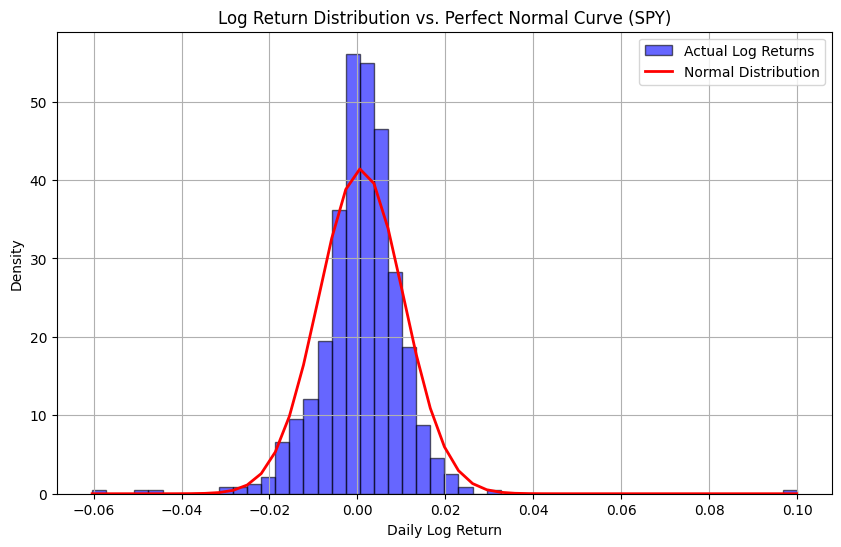

In [6]:
import scipy.stats as stats

# Plot the actual histogram of log returns
plt.figure(figsize=(10, 6))
count, bins, ignored = plt.hist(df['Log_Return'], bins=50, density=True, alpha=0.6, color='b', edgecolor='black', label='Actual Log Returns')

# Overlay a perfect theoretical normal distribution (bell curve) for comparison
mu, sigma = df['Log_Return'].mean(), df['Log_Return'].std()
plt.plot(bins, 1/(sigma * np.sqrt(2*np.pi)) * np.exp( - (bins - mu)**2 / (2 * sigma**2) ), linewidth=2, color='r', label='Normal Distribution')

plt.title(f'Log Return Distribution vs. Perfect Normal Curve ({TICKER})')
plt.xlabel('Daily Log Return')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.show()

### Return Distribution Analysis
The daily log return distribution for SPY does **not** look perfectly normal. 

When comparing the blue bars (actual returns) to the red line (the theoretical normal bell curve), we can observe:
1. **Higher Peak (Leptokurtosis):** The center of the actual distribution is taller and more tightly clustered around the mean than a normal distribution expects.
2. **Fat Tails:** The extreme edges (the far left and far right ends of the graph) have actual data points that extend further out than the red normal curve. This means that extreme market shocks (massive sell-offs or massive single-day rallies) occur much more frequently in real life than standard Gaussian math predicts.

In [7]:
import yfinance as yf
import numpy as np
import pandas as pd

# 1. Fetch data
TICKERS = ["AAPL", "GLD", "TLT"]
df_portfolio = yf.download(TICKERS, start="2023-01-01", end="2026-01-01")

# 2. Run our optimized multi-asset indicator loop
for ticker in TICKERS:
    df_portfolio[('EMA', ticker)] = df_portfolio[('Close', ticker)].ewm(span=14, adjust=False).mean()
    df_portfolio[('Price_Change', ticker)] = df_portfolio[('Close', ticker)].diff()
    df_portfolio[('Gain', ticker)] = np.where(df_portfolio[('Price_Change', ticker)] > 0, df_portfolio[('Price_Change', ticker)], 0)
    df_portfolio[('Loss', ticker)] = np.where(df_portfolio[('Price_Change', ticker)] < 0, -df_portfolio[('Price_Change', ticker)], 0)
    
    roll_gain = df_portfolio[('Gain', ticker)].rolling(window=14).mean()
    roll_loss = df_portfolio[('Loss', ticker)].rolling(window=14).mean()
    df_portfolio[('RSI', ticker)] = 100 - (100 / (1 + (roll_gain / roll_loss)))

df_portfolio.dropna(inplace=True)

# 3. Display the data as an interactive HTML table
df_portfolio

[*********************100%***********************]  3 of 3 completed


Price            Close                               High              \
Ticker            AAPL         GLD        TLT        AAPL         GLD   
Date                                                                    
2023-01-23  138.755020  179.630005  92.195717  140.928144  179.690002   
2023-01-24  140.151321  180.279999  93.521553  140.770812  180.320007   
2023-01-25  139.492493  181.110001  93.748344  140.052972  181.220001   
2023-01-26  141.557465  179.470001  93.312218  141.842618  180.270004   
2023-01-27  143.494568  179.220001  93.076714  144.772875  179.720001   
...                ...         ...        ...         ...         ...   
2025-12-24  273.302216  411.929993  86.395973  274.919206  412.630005   
2025-12-26  272.892975  416.739990  86.111359  274.859323  418.450012   
2025-12-29  273.252350  398.600006  86.435234  273.851213  403.760010   
2025-12-30  272.573578  398.890015  86.229134  273.571723  403.799988   
2025-12-31  271.355835  396.309998  85.542137  273.172467  400.130005   

Price                         Low                               Open  ...  \
Ticker            TLT        AAPL         GLD        TLT        AAPL  ...   
Date                                                                  ...   
2023-01-23  92.631837  135.598585  177.779999  92.012547  135.814915  ...   
2023-01-24  93.722164  137.958542  178.350006  91.925353  137.968370  ...   
2023-01-25  94.123408  136.493391  179.289993  93.015659  138.538680  ...   
2023-01-26  93.896617  139.531831  178.460007  92.884815  140.780640  ...   
2023-01-27  93.294774  140.692141  178.259995  92.553371  140.770807  ...   
...               ...         ...         ...        ...         ...  ...   
2025-12-24  86.445048  271.695216  408.829987  86.023030  271.834940  ...   
2025-12-26  86.533377  272.353968  414.750000  85.973958  273.651575  ...   
2025-12-29  86.435234  271.844961  395.329987  86.160433  272.184327  ...   
2025-12-30  86.405793  271.775074  398.559998  86.042658  272.304090  ...   
2025-12-31  86.278216  271.246054  395.589996  85.512688  272.553622  ...   

Price              EMA Price_Change      Gain       Loss        RSI  \
Ticker             GLD          GLD       GLD        GLD        GLD   
Date                                                                  
2023-01-23  176.419365     0.340012  0.340012   0.000000  74.250144   
2023-01-24  176.934117     0.649994  0.649994   0.000000  75.163749   
2023-01-25  177.490901     0.830002  0.830002   0.000000  74.059288   
2023-01-26  177.754781    -1.639999  0.000000   1.639999  76.277127   
2023-01-27  177.950144    -0.250000  0.000000   0.250000  69.552839   
...                ...          ...       ...        ...        ...   
2025-12-24  399.169853    -1.710022  0.000000   1.710022  87.484847   
2025-12-26  401.512538     4.809998  4.809998   0.000000  90.725777   
2025-12-29  401.124200   -18.139984  0.000000  18.139984  62.131803   
2025-12-30  400.826309     0.290009  0.290009   0.000000  60.915840   
2025-12-31  400.224134    -2.580017  0.000000   2.580017  56.777448   

Price             EMA Price_Change      Gain      Loss        RSI  
Ticker            TLT          TLT       TLT       TLT        TLT  
Date                                                               
2023-01-23  92.078648    -0.436127  0.000000  0.436127  62.470441  
2023-01-24  92.271036     1.325836  1.325836  0.000000  65.550685  
2023-01-25  92.468010     0.226791  0.226791  0.000000  63.312247  
2023-01-26  92.580571    -0.436127  0.000000  0.436127  60.595598  
2023-01-27  92.646724    -0.235504  0.000000  0.235504  54.832569  
...               ...          ...       ...       ...        ...  
2025-12-24  86.139347     0.520157  0.520157  0.000000  47.606379  
2025-12-26  86.135615    -0.284615  0.000000  0.284615  48.949351  
2025-12-29  86.175564     0.323875  0.323875  0.000000  56.260156  
2025-12-30  86.182707    -0.206100  0.000000  0.206100  52.650145  
2025-12-31  86.0972

In [8]:
# 1. Initialize Signal and Weight columns for each asset
for ticker in TICKERS:
    df_portfolio[('Signal', ticker)] = 0
    
    # Apply your optimized Entry condition
    buy_cond = (df_portfolio[('Close', ticker)] > df_portfolio[('EMA', ticker)]) & (df_portfolio[('RSI', ticker)] < 80)
    df_portfolio.loc[buy_cond, ('Signal', ticker)] = 1
    
    # Apply your optimized Exit condition
    exit_cond = (df_portfolio[('Close', ticker)] < df_portfolio[('EMA', ticker)]) | (df_portfolio[('RSI', ticker)] > 80)
    df_portfolio.loc[exit_cond, ('Signal', ticker)] = 0

# 2. Count how many total assets are signaling a BUY each day
# We sum across the 'Signal' level horizontally (axis=1)
df_portfolio['Total_Active_Signals'] = df_portfolio['Signal'].sum(axis=1)

# 3. Calculate the portfolio weight dynamically for each asset
for ticker in TICKERS:
    # If Total_Active_Signals is 0, weight will be 0 to avoid DivisionByZero
    df_portfolio[('Weight', ticker)] = np.where(
        df_portfolio['Total_Active_Signals'] > 0,
        df_portfolio[('Signal', ticker)] / df_portfolio['Total_Active_Signals'],
        0
    )

# Display a subset of the table to verify the weighting works
df_portfolio[['Signal', 'Weight', 'Total_Active_Signals']].tail(10)

Price      Signal         Weight           Total_Active_Signals
Ticker       AAPL GLD TLT   AAPL  GLD  TLT                     
Date                                                           
2025-12-17      0   0   0    0.0  0.0  0.0                    0
2025-12-18      0   1   1    0.0  0.5  0.5                    2
2025-12-19      0   1   0    0.0  1.0  0.0                    1
2025-12-22      0   0   0    0.0  0.0  0.0                    0
2025-12-23      0   0   0    0.0  0.0  0.0                    0
2025-12-24      0   0   1    0.0  0.0  1.0                    1
2025-12-26      0   0   0    0.0  0.0  0.0                    0
2025-12-29      0   0   1    0.0  0.0  1.0                    1
2025-12-30      0   0   1    0.0  0.0  1.0                    1
2025-12-31      0   0   0    0.0  0.0  0.0                    0

In [9]:
# 1. Initialize a column to store our overall daily portfolio returns
df_portfolio['Portfolio_Daily_Return'] = 0.0

# 2. Calculate shifted weights and daily returns for each asset
for ticker in TICKERS:
    # Shift weights by 1 day to prevent look-ahead bias (Buy at close, collect tomorrow)
    df_portfolio[('Shifted_Weight', ticker)] = df_portfolio[('Weight', ticker)].shift(1)
    
    # Calculate each asset's daily log returns
    df_portfolio[('Log_Return', ticker)] = np.log(df_portfolio[('Close', ticker)] / df_portfolio[('Close', ticker)].shift(1))
    
    # Add this asset's contribution to our overall daily portfolio return
    df_portfolio['Portfolio_Daily_Return'] += df_portfolio[('Shifted_Weight', ticker)] * df_portfolio[('Log_Return', ticker)]

# Drop the new NaN rows from shifting
df_portfolio.dropna(inplace=True)

# 3. Compute Final Comparative Performance Metrics
# Portfolio Metrics
port_annualized_return = df_portfolio['Portfolio_Daily_Return'].mean() * 252
port_annualized_vol = df_portfolio['Portfolio_Daily_Return'].std() * np.sqrt(252)
port_sharpe = port_annualized_return / port_annualized_vol

# Print out your official Multi-Asset Portfolio Report
print("\n" + "="*50)
print("     FINAL MULTI-ASSET PORTFOLIO RESULTS      ")
print("="*50)
print(f"Annualized Return:     {port_annualized_return * 100:.2f}%")
print(f"Annualized Volatility: {port_annualized_vol * 100:.2f}%")
print(f"Annualized Sharpe:     {port_sharpe:.2f}")
print("====================================" + "\n")


     FINAL MULTI-ASSET PORTFOLIO RESULTS      
Annualized Return:     17.79%
Annualized Volatility: 14.56%
Annualized Sharpe:     1.22

